<a href="https://colab.research.google.com/github/pruthvirajbb-byte/DAV/blob/main/EXP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

INDIAN WEATHER AND AIR QUALITY ANALYSIS
Running in Google Colab. Please upload your 'archive (3).zip' file:


Saving archive (3).zip to archive (3) (1).zip

Extracted files to: ./extracted_data
Reading datasets from path: ./extracted_data

DATASETS LOADED SUCCESSFULLY!

Weather Dataset: (124750, 14)
Air Quality Dataset: (77400, 19)
Cities Dataset: (50, 6)


1. DATASET INFORMATION
--------------------------------------------------

WEATHER DATA
         date      city  temperature_2m_max  temperature_2m_min  temperature_2m_mean  apparent_temperature_max  \
0  2020-01-01  Agartala               26.20               16.20                20.50                     28.30   
1  2020-01-02  Agartala               26.50               15.00                20.20                     28.80   
2  2020-01-03  Agartala               20.20               15.70                18.00                     21.40   
3  2020-01-04  Agartala               21.80               14.70                17.90                     22.70   
4  2020-01-05  Agartala               21.80               13.60                17.00        

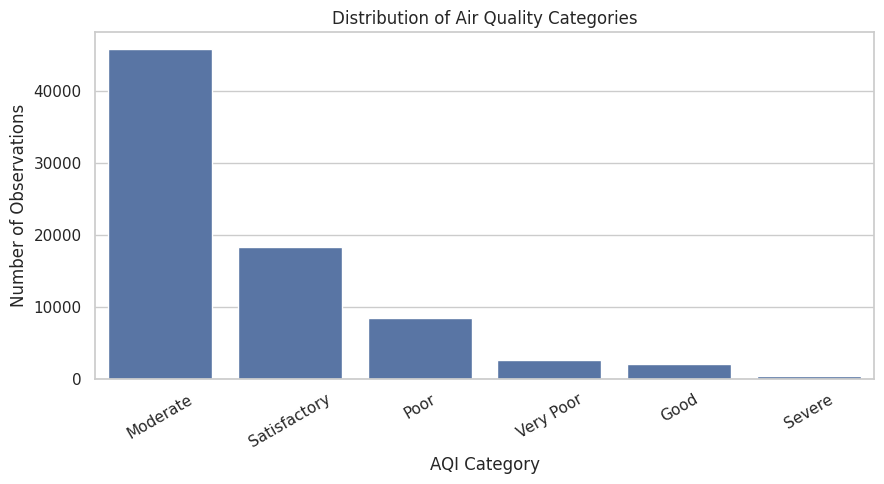

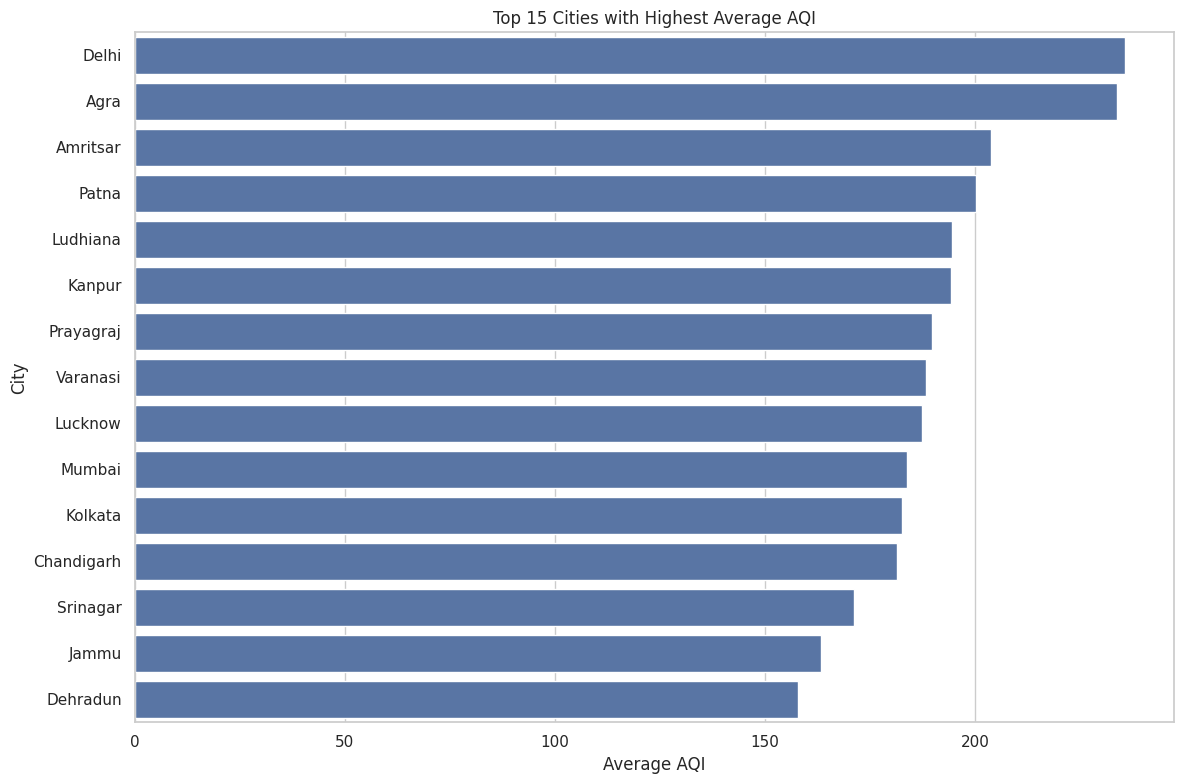

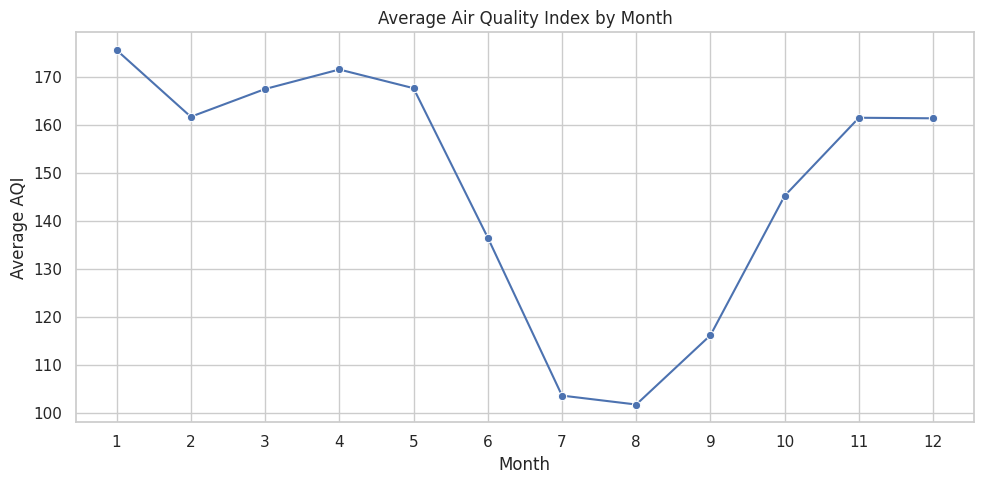

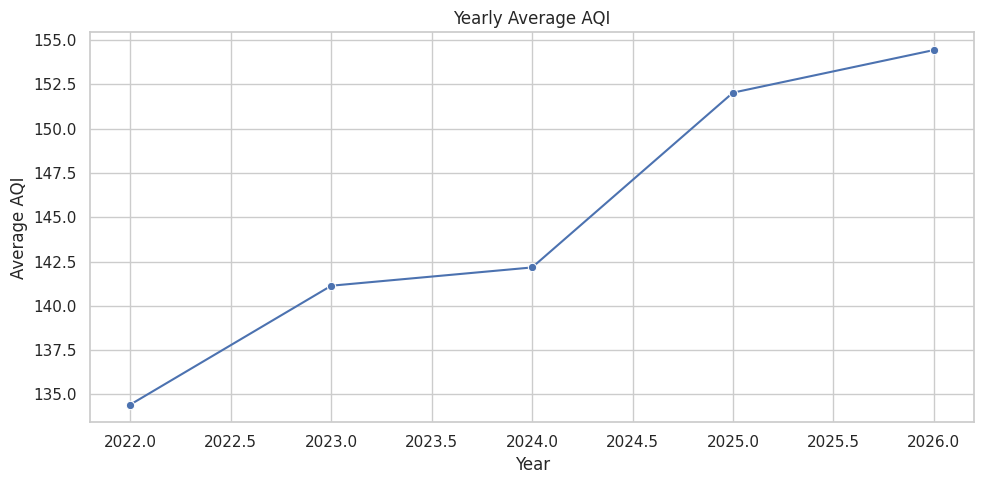

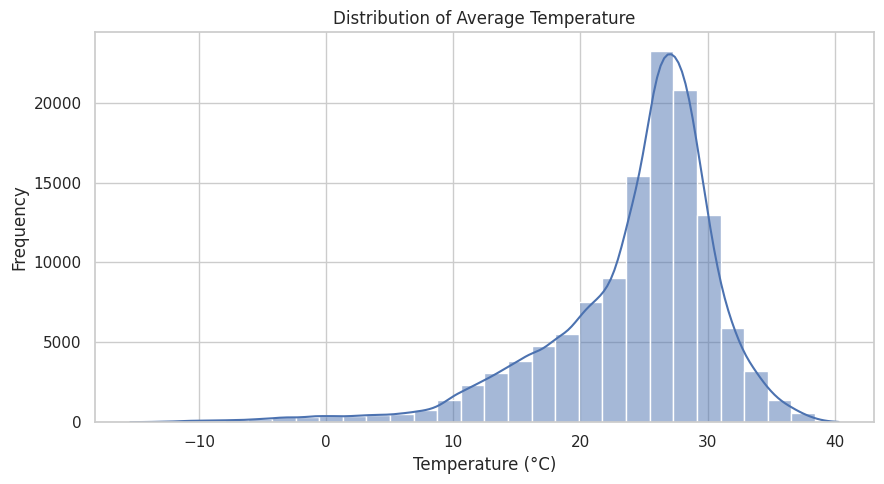

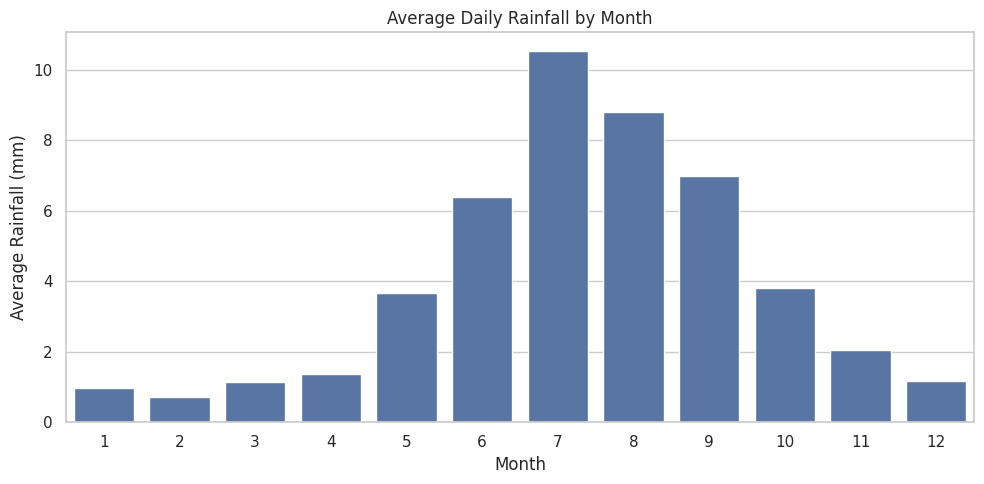

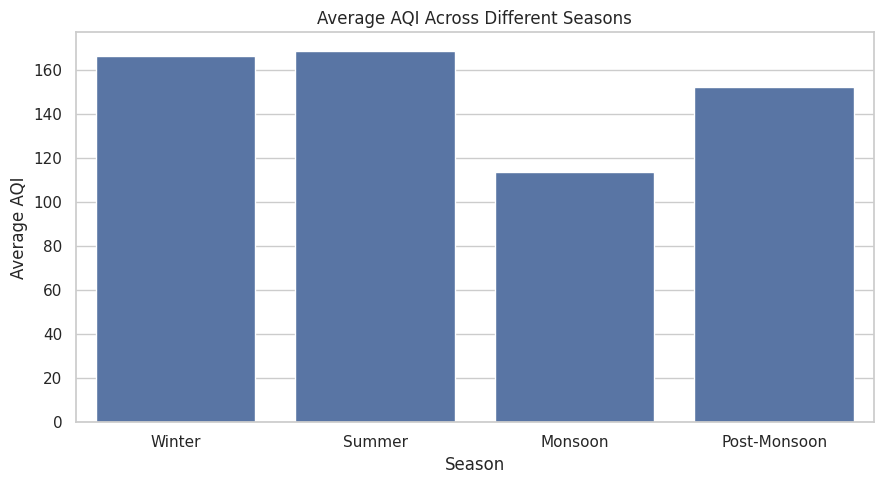

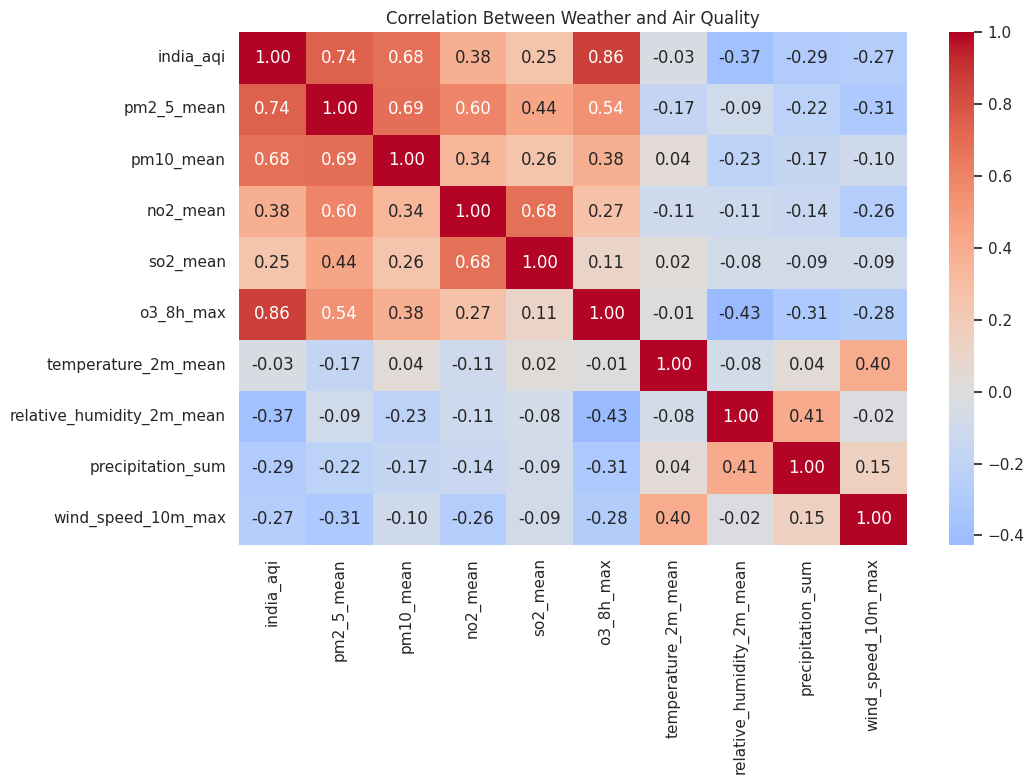

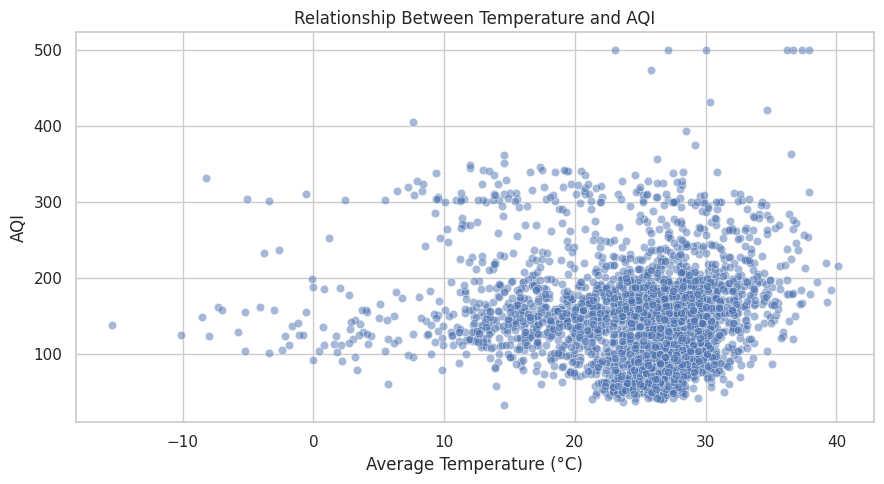

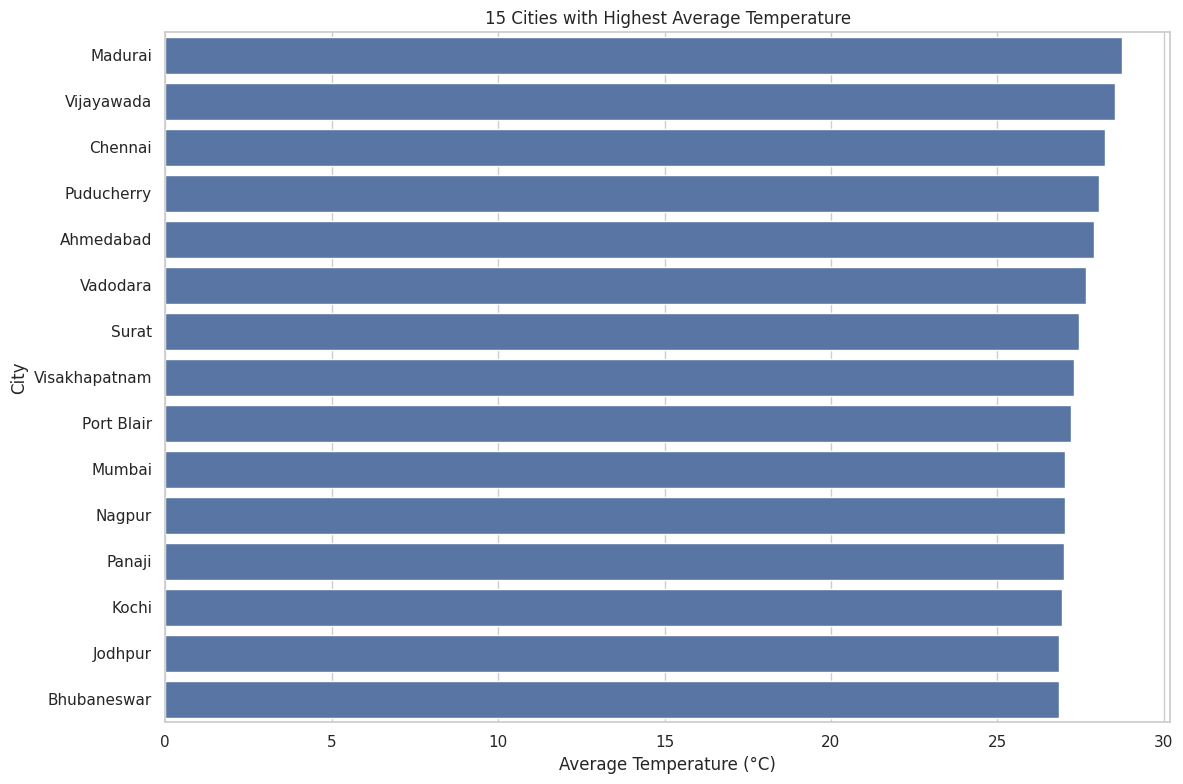



6. IMPORTANT DATA INSIGHTS

1. MOST POLLUTED CITY (BY DATASET AVERAGE):
Delhi : 235.51

2. LOWEST AVERAGE AQI CITY:
Port Blair : 81.59

3. MONTH WITH HIGHEST AVERAGE AQI:
1

4. MONTH WITH LOWEST AVERAGE AQI:
8

5. CITY WITH HIGHEST AVERAGE TEMPERATURE:
Madurai : 28.76 °C

6. MOST COMMON AIR QUALITY CATEGORY:
Moderate

7. SEASON WITH HIGHEST AVERAGE AQI:
Summer

8. VARIABLES MOST POSITIVELY CORRELATED WITH AQI:
o3_8h_max    0.86
pm2_5_mean   0.74
pm10_mean    0.68
Name: india_aqi, dtype: float64

9. VARIABLES MOST NEGATIVELY CORRELATED WITH AQI:
wind_speed_10m_max          -0.27
precipitation_sum           -0.29
relative_humidity_2m_mean   -0.37
Name: india_aqi, dtype: float64


7. FINAL CONCLUSION

The project analyzed weather and air quality data across
50 Indian cities.

The analysis included:

1. Data cleaning and preprocessing.
2. Missing value and duplicate checking.
3. Exploratory data analysis.
4. City-wise pollution analysis.
5. Monthly and yearly AQI trends.
6. Temperature a

In [13]:
# ============================================================
# DAES EXPERIENTIAL LEARNING ASSIGNMENT
# PROJECT: INDIAN WEATHER AND AIR QUALITY ANALYSIS (2020-2026)
# ============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("=" * 65)
print("INDIAN WEATHER AND AIR QUALITY ANALYSIS")
print("=" * 65)


# 2. LOAD DATASET

# Dynamic path configuration for Google Colab vs Local environment
try:
    from google.colab import files
    print("Running in Google Colab. Please upload your 'archive (3).zip' file:")
    uploaded = files.upload()
    zip_name = next((name for name in uploaded if name.lower().endswith(".zip")), None)
    if zip_name:
        DATA_PATH = "./extracted_data"
        os.makedirs(DATA_PATH, exist_ok=True)
        with zipfile.ZipFile(zip_name, 'r') as zf:
            zf.extractall(DATA_PATH)
        print(f"\nExtracted files to: {DATA_PATH}")
    else:
        DATA_PATH = "."
except ImportError:
    # Fallback to local path if running outside Google Colab
    DATA_PATH = r"C:\Users\HP\Downloads\archive (3)"

print(f"Reading datasets from path: {DATA_PATH}")
weather = pd.read_csv(os.path.join(DATA_PATH, "weather_daily.csv"))
air = pd.read_csv(os.path.join(DATA_PATH, "air_quality_daily.csv"))
cities = pd.read_csv(os.path.join(DATA_PATH, "cities.csv"))

print("\nDATASETS LOADED SUCCESSFULLY!")

print("\nWeather Dataset:", weather.shape)
print("Air Quality Dataset:", air.shape)
print("Cities Dataset:", cities.shape)


# 3. DATA UNDERSTANDING

print("\n\n1. DATASET INFORMATION")
print("-" * 50)

print("\nWEATHER DATA")
print(weather.head())
print("\n")
weather.info()

print("\nAIR QUALITY DATA")
print(air.head())
print("\n")
air.info()

print("\nCITIES DATA")
print(cities.head())


# 4. STATISTICAL SUMMARY

print("\n\n2. STATISTICAL SUMMARY")
print("-" * 50)

print("\nWeather Statistics:")
print(weather.describe())

print("\nAir Quality Statistics:")
print(air.describe())


# 5. DATA CLEANING

print("\n\n3. DATA CLEANING")
print("-" * 50)

# Standardize column names
for df in [weather, air, cities]:
    df.columns = df.columns.str.strip().str.lower()

# Remove duplicate records
print("\nDuplicates Before Cleaning:")
print("Weather:", weather.duplicated().sum())
print("Air Quality:", air.duplicated().sum())
print("Cities:", cities.duplicated().sum())

weather = weather.drop_duplicates().copy()
air = air.drop_duplicates().copy()
cities = cities.drop_duplicates().copy()

# Convert dates
weather["date"] = pd.to_datetime(weather["date"], errors="coerce")
air["date"] = pd.to_datetime(air["date"], errors="coerce")

# Standardize city names
for df in [weather, air, cities]:
    df["city"] = df["city"].astype("string").str.strip().str.title()

# Convert numeric columns
for df in [weather, air, cities]:
    for col in df.columns:
        if col not in [
            "date", "city", "state", "region",
            "india_aqi_category", "india_aqi_pm_category",
            "dominant_pollutant"
        ]:
            df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove invalid date rows
weather = weather.dropna(subset=["date", "city"])
air = air.dropna(subset=["date", "city"])

# Check missing values
print("\nMissing Values in Weather:")
print(weather.isnull().sum())

print("\nMissing Values in Air Quality:")
print(air.isnull().sum())

# Check physically invalid values
if "precipitation_sum" in weather:
    weather.loc[
        weather["precipitation_sum"] < 0,
        "precipitation_sum"
    ] = np.nan

if "relative_humidity_2m_mean" in weather:
    weather.loc[
        ~weather["relative_humidity_2m_mean"].between(0, 100),
        "relative_humidity_2m_mean"
    ] = np.nan

for col in ["india_aqi", "india_aqi_pm", "us_aqi_max"]:
    if col in air:
        air.loc[air[col] < 0, col] = np.nan

print("\nData Cleaning Completed!")


# 6. DATA PREPROCESSING

print("\n\n4. DATA PREPROCESSING")
print("-" * 50)

# Extract year, month and day
for df in [weather, air]:
    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["month_name"] = df["date"].dt.month_name()
    df["day"] = df["date"].dt.day

    # Create seasons
    df["season"] = df["month"].map({
        12: "Winter",
        1: "Winter",
        2: "Winter",
        3: "Summer",
        4: "Summer",
        5: "Summer",
        6: "Monsoon",
        7: "Monsoon",
        8: "Monsoon",
        9: "Monsoon",
        10: "Post-Monsoon",
        11: "Post-Monsoon"
    })

# Merge weather and air quality datasets
combined = pd.merge(
    weather,
    air,
    on=["date", "city"],
    how="inner",
    suffixes=("_weather", "_air")
)

# Add city information
combined = pd.merge(
    combined,
    cities,
    on="city",
    how="left"
)

print("\nCombined Dataset Shape:", combined.shape)
print("\nCombined Dataset:")
print(combined.head())

print("\nCommon Date Range:")
print(combined["date"].min())
print(combined["date"].max())


# 7. EXPLORATORY DATA ANALYSIS

print("\n\n5. EXPLORATORY DATA ANALYSIS")
print("-" * 50)

print("\nTotal Weather Records:", len(weather))
print("Total Air Quality Records:", len(air))
print("Total Combined Records:", len(combined))

print("\nNumber of Cities:", combined["city"].nunique())

print("\nAverage Temperature:",
      round(weather["temperature_2m_mean"].mean(), 2))

print("\nAverage AQI:",
      round(air["india_aqi"].mean(), 2))

print("\nMaximum AQI:",
      air["india_aqi"].max())

print("\nMinimum AQI:",
      air["india_aqi"].min())


# 8. VISUALIZATION 1 - AQI CATEGORY DISTRIBUTION

plt.figure(figsize=(9, 5))

sns.countplot(
    data=air,
    x="india_aqi_category",
    order=air["india_aqi_category"].value_counts().index
)

plt.title("Distribution of Air Quality Categories")
plt.xlabel("AQI Category")
plt.ylabel("Number of Observations")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# 9. VISUALIZATION 2 - CITY-WISE AQI

city_aqi = air.groupby("city")["india_aqi"].mean().sort_values(
    ascending=False
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=city_aqi.head(15).values,
    y=city_aqi.head(15).index
)

plt.title("Top 15 Cities with Highest Average AQI")
plt.xlabel("Average AQI")
plt.ylabel("City")
plt.tight_layout()
plt.show()


# 10. VISUALIZATION 3 - MONTHLY AQI TREND

monthly_aqi = air.groupby("month")["india_aqi"].mean()

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_aqi.index,
    y=monthly_aqi.values,
    marker="o"
)

plt.title("Average Air Quality Index by Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()


# 11. VISUALIZATION 4 - YEARLY AQI TREND

yearly_aqi = air.groupby("year")["india_aqi"].mean()

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=yearly_aqi.index,
    y=yearly_aqi.values,
    marker="o"
)

plt.title("Yearly Average AQI")
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.tight_layout()
plt.show()


# 12. VISUALIZATION 5 - TEMPERATURE DISTRIBUTION

plt.figure(figsize=(9, 5))

sns.histplot(
    weather["temperature_2m_mean"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Average Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# 13. VISUALIZATION 6 - RAINFALL BY MONTH

monthly_rainfall = weather.groupby("month")[
    "precipitation_sum"
].mean()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_rainfall.index,
    y=monthly_rainfall.values
)

plt.title("Average Daily Rainfall by Month")
plt.xlabel("Month")
plt.ylabel("Average Rainfall (mm)")
plt.tight_layout()
plt.show()


# 14. VISUALIZATION 7 - SEASONAL AQI

season_order = [
    "Winter", "Summer", "Monsoon", "Post-Monsoon"
]

seasonal_aqi = air.groupby("season")["india_aqi"].mean()
seasonal_aqi = seasonal_aqi.reindex(season_order)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=seasonal_aqi.index,
    y=seasonal_aqi.values
)

plt.title("Average AQI Across Different Seasons")
plt.xlabel("Season")
plt.ylabel("Average AQI")
plt.tight_layout()
plt.show()


# 15. VISUALIZATION 8 - CORRELATION HEATMAP

correlation_columns = [
    "india_aqi",
    "pm2_5_mean",
    "pm10_mean",
    "no2_mean",
    "so2_mean",
    "o3_8h_max",
    "temperature_2m_mean",
    "relative_humidity_2m_mean",
    "precipitation_sum",
    "wind_speed_10m_max"
]

correlation_data = combined[
    [col for col in correlation_columns if col in combined.columns]
]

correlation = correlation_data.corr(numeric_only=True)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Weather and Air Quality")
plt.tight_layout()
plt.show()


# 16. VISUALIZATION 9 - TEMPERATURE VS AQI

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=combined.sample(
        min(3000, len(combined)),
        random_state=42
    ),
    x="temperature_2m_mean",
    y="india_aqi",
    alpha=0.5
)

plt.title("Relationship Between Temperature and AQI")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("AQI")
plt.tight_layout()
plt.show()


# 17. VISUALIZATION 10 - CITY-WISE TEMPERATURE

city_temperature = weather.groupby("city")[
    "temperature_2m_mean"
].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=city_temperature.head(15).values,
    y=city_temperature.head(15).index
)

plt.title("15 Cities with Highest Average Temperature")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("City")
plt.tight_layout()
plt.show()


# 18. MEANINGFUL INSIGHTS

print("\n\n6. IMPORTANT DATA INSIGHTS")
print("=" * 65)

# Highest and lowest AQI cities
highest_city = city_aqi.idxmax()
lowest_city = city_aqi.idxmin()

print("\n1. MOST POLLUTED CITY (BY DATASET AVERAGE):")
print(highest_city, ":", round(city_aqi.max(), 2))

print("\n2. LOWEST AVERAGE AQI CITY:")
print(lowest_city, ":", round(city_aqi.min(), 2))

# Highest and lowest AQI month
highest_month = monthly_aqi.idxmax()
lowest_month = monthly_aqi.idxmin()

print("\n3. MONTH WITH HIGHEST AVERAGE AQI:")
print(highest_month)

print("\n4. MONTH WITH LOWEST AVERAGE AQI:")
print(lowest_month)

# Highest temperature city
print("\n5. CITY WITH HIGHEST AVERAGE TEMPERATURE:")
print(city_temperature.idxmax(),
      ":", round(city_temperature.max(), 2), "°C")

# Most common AQI category
print("\n6. MOST COMMON AIR QUALITY CATEGORY:")
print(air["india_aqi_category"].mode()[0])

# Seasonal comparison
print("\n7. SEASON WITH HIGHEST AVERAGE AQI:")
print(seasonal_aqi.idxmax())

# Correlation
aqi_correlations = correlation["india_aqi"].drop(
    labels=["india_aqi"],
    errors="ignore"
).sort_values(ascending=False)

print("\n8. VARIABLES MOST POSITIVELY CORRELATED WITH AQI:")
print(aqi_correlations.head(3))

print("\n9. VARIABLES MOST NEGATIVELY CORRELATED WITH AQI:")
print(aqi_correlations.tail(3))


# 19. FINAL CONCLUSION

print("\n\n7. FINAL CONCLUSION")
print("=" * 65)

print("""
The project analyzed weather and air quality data across
50 Indian cities.

The analysis included:

1. Data cleaning and preprocessing.
2. Missing value and duplicate checking.
3. Exploratory data analysis.
4. City-wise pollution analysis.
5. Monthly and yearly AQI trends.
6. Temperature and rainfall analysis.
7. Seasonal air quality comparison.
8. Correlation between weather and pollutants.
9. Data visualization.
10. Generation of meaningful insights.

The analysis helps identify differences in air quality
between cities and changes across seasons and months.

It also explores relationships between weather conditions
and air pollution.

These findings can help improve awareness of air quality
patterns and support further environmental analysis.

The results show associations, not proof of causation.
The air-quality dataset starts later than the weather
dataset, and 2022 and 2026 are partial years.
Therefore, annual comparisons should focus on complete
years wherever possible.
""")

# 20. SAVE CLEANED DATASETS

weather.to_csv("weather_cleaned.csv", index=False)
air.to_csv("air_quality_cleaned.csv", index=False)
combined.to_csv("weather_air_quality_combined.csv", index=False)

print("\nCLEANED DATASETS SAVED SUCCESSFULLY!")

print("\nPROJECT COMPLETED SUCCESSFULLY!")
print("=" * 65)